In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## roc-pr-curves

**Figure 1: ROC curves of membership inference attacks against a CIFAR-10 model.** Both axes are log scale, the percentage after each attack in the legend is its balanced accuracy, markers sit at FPR = 0.01%, 0.1%, 1% and 10%, and the thin dashed diagonal is a random-guess attack. At 0.1% FPR, Ours reaches 8.4% TPR, 3.8× the best prior attack (Long et al., 2.2%), while Yeom et al. has a higher accuracy (59.5%) than Long et al. (53.5%) yet finds almost no members there.

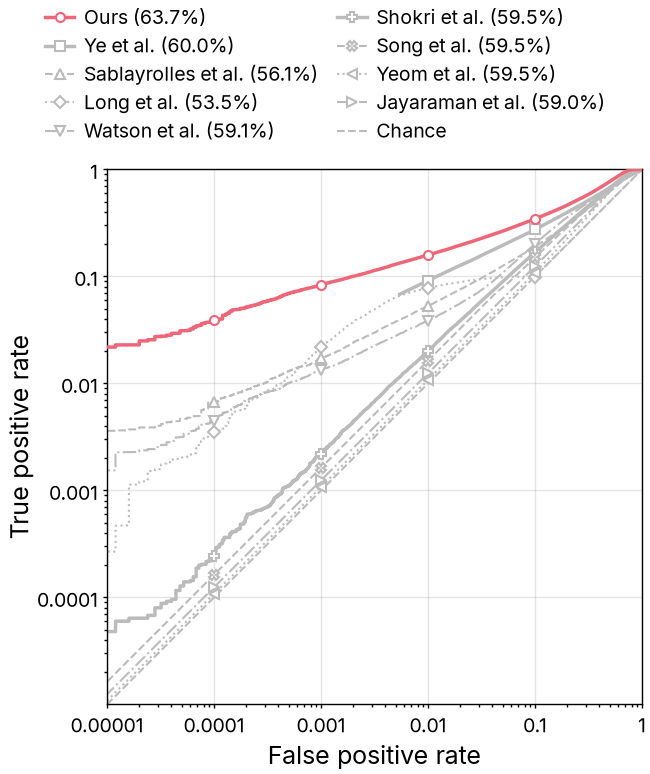

In [2]:
with open("../roc-pr-curves.json") as f:
    data = json.load(f)

markers = ["o", "s", "^", "D", "v", "P", "X", "<", ">"]
baseline_styles = ["-", "--", ":", "-."]
marker_fprs = np.array([1e-4, 1e-3, 1e-2, 1e-1])

fig, ax = plt.subplots(figsize=(3.25, 3.25))
for i, curve in enumerate(data["curves"]):
    fpr, tpr = np.array(curve["fpr"]), np.array(curve["tpr"])
    if curve["method"] == "Ours":
        color, linestyle = colors["ours"], "-"
    else:
        color, linestyle = colors["neutral"], baseline_styles[(i - 1) % 4]
    ax.plot(fpr, tpr, linestyle=linestyle, linewidth=paper.dashed_width if linestyle != "-" else None, color=color, zorder=3 if curve["method"] == "Ours" else 2)
    covered = marker_fprs[marker_fprs >= fpr[0]]
    marker_tprs = np.exp(np.interp(np.log(covered), np.log(fpr), np.log(tpr)))
    ax.plot(covered, marker_tprs, markers[i], color=color, zorder=3 if curve["method"] == "Ours" else 2)
    ax.plot([], [], linestyle=linestyle, linewidth=paper.dashed_width if linestyle != "-" else None, marker=markers[i], color=color,
            label=f"{curve['method']} ({curve['attack_accuracy_percent']}%)")
ax.plot(data["chance_line"]["fpr"], data["chance_line"]["tpr"], linestyle="--", linewidth=0.75,
        color=colors["neutral"], zorder=1, label="Chance")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1e-5, 1)
ax.set_ylim(1e-5, 1)
ax.set_xticks([1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1], labels=["0.00001", "0.0001", "0.001", "0.01", "0.1", "1"])
ax.set_yticks([1e-4, 1e-3, 1e-2, 1e-1, 1], labels=["0.0001", "0.001", "0.01", "0.1", "1"])
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
fig.legend(*ax.get_legend_handles_labels(), loc="outside upper center", ncol=2, frameon=False, borderaxespad=0)

fit_height(fig, ax, aspect=1.0)
fig.savefig("roc-pr-curves.pdf")
fig.savefig("roc-pr-curves.png")
plt.show()